# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site Air Quality)
- **Nama:** [Isi Nama Lengkap Anda]
- **Email:** [Isi Email Anda]
- **ID Dicoding:** [Isi Username/ID Dicoding Anda]

## Menentukan Pertanyaan Bisnis

**Konteks.** Dataset berisi pengukuran **per jam** enam polutan udara (PM2.5, PM10, SO2, NO2, CO, O3) dan enam variabel meteorologi dari **12 stasiun pemantauan di Beijing** selama **1 Maret 2013 – 28 Februari 2017**. Periode ini bertepatan dengan pelaksanaan *Air Pollution Prevention and Control Action Plan* (2013–2017) pemerintah China. Sudut pandang analisis adalah **Dinas Lingkungan Hidup Kota Beijing** yang perlu (1) memprioritaskan wilayah intervensi, (2) mengevaluasi tren & merencanakan kebijakan musiman, dan (3) menyusun sistem peringatan dini berbasis kondisi cuaca.

Fokus polutan adalah **PM2.5** karena paling berbahaya bagi kesehatan dan menjadi indikator utama kualitas udara. Acuan yang digunakan adalah **baku mutu harian PM2.5 China (GB 3095-2012, Grade II) sebesar 75 µg/m³**.

- **Pertanyaan 1:** Di antara 12 stasiun pemantauan di Beijing, stasiun mana yang mencatat **rata-rata konsentrasi PM2.5 tertinggi** dan **persentase hari melampaui baku mutu harian 75 µg/m³ terbesar** selama periode Maret 2013 – Februari 2017, sehingga dapat dijadikan prioritas lokasi intervensi pengendalian polusi?
- **Pertanyaan 2:** Berapa **persentase perubahan rata-rata PM2.5 per tahun pemantauan** (Maret–Februari) dari 2013/14 hingga 2016/17, serta pada **musim, bulan, dan jam** apa rata-rata PM2.5 mencapai puncaknya selama periode tersebut, sebagai dasar evaluasi kebijakan dan penjadwalan pembatasan aktivitas sumber emisi?
- **Pertanyaan 3:** Seberapa besar **perbedaan rata-rata PM2.5 antara kondisi angin tenang (≤ 1 m/s) dan angin kencang (> 4 m/s)**, serta **arah angin** mana yang berasosiasi dengan PM2.5 tertinggi selama Maret 2013 – Februari 2017, sehingga prakiraan cuaca dapat dijadikan pemicu peringatan dini polusi udara?

**Pemetaan SMART:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| **Specific** | PM2.5 per stasiun (12 stasiun Beijing) | PM2.5 per tahun pemantauan, musim, bulan, dan jam | PM2.5 vs. kecepatan & arah angin |
| **Measurable** | Rata-rata µg/m³ & % hari > 75 µg/m³ | % perubahan tahunan, rata-rata per musim/bulan/jam | Selisih rata-rata (µg/m³ & %) antar kelompok angin |
| **Action-oriented** | Menentukan stasiun/wilayah prioritas intervensi | Mengevaluasi kebijakan & menjadwalkan pembatasan emisi | Menentukan pemicu (*trigger*) peringatan dini |
| **Relevant** | Alokasi sumber daya pengendalian polusi | Evaluasi *Action Plan* 2013–2017 & kesehatan publik | Sistem peringatan dini berbasis prakiraan cuaca |
| **Time-bound** | Maret 2013 – Februari 2017 | 2013/14 – 2016/17 | Maret 2013 – Februari 2017 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import os

import folium
import branca.colormap as cm
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

# Konstanta yang dipakai di seluruh notebook
PM25_STANDARD = 75          # Baku mutu harian PM2.5 China (GB 3095-2012, Grade II), µg/m³
HIGHLIGHT = "#C0392B"       # warna sorotan (nilai terpenting)
BASE = "#B8C4CE"            # warna netral untuk nilai lainnya
ACCENT = "#2E86AB"          # warna utama garis/tren

## Data Wrangling

### Gathering Data

Dataset terdiri atas **12 berkas CSV** (satu berkas per stasiun) yang disimpan pada folder `data/`. Seluruh berkas memiliki struktur kolom yang sama sehingga dapat digabung secara vertikal (`pd.concat`) menjadi satu DataFrame.

In [2]:
data_files = sorted(glob.glob(os.path.join("data", "PRSA_Data_*.csv")))
print(f"Jumlah berkas ditemukan: {len(data_files)}")
for f in data_files:
    print(" -", os.path.basename(f))

Jumlah berkas ditemukan: 12
 - PRSA_Data_Aotizhongxin_20130301-20170228.csv
 - PRSA_Data_Changping_20130301-20170228.csv
 - PRSA_Data_Dingling_20130301-20170228.csv
 - PRSA_Data_Dongsi_20130301-20170228.csv
 - PRSA_Data_Guanyuan_20130301-20170228.csv
 - PRSA_Data_Gucheng_20130301-20170228.csv
 - PRSA_Data_Huairou_20130301-20170228.csv
 - PRSA_Data_Nongzhanguan_20130301-20170228.csv
 - PRSA_Data_Shunyi_20130301-20170228.csv
 - PRSA_Data_Tiantan_20130301-20170228.csv
 - PRSA_Data_Wanliu_20130301-20170228.csv
 - PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [3]:
df_list = [pd.read_csv(f) for f in data_files]
air_df = pd.concat(df_list, ignore_index=True)

print(f"Ukuran data gabungan: {air_df.shape[0]:,} baris x {air_df.shape[1]} kolom")
air_df.head()

Ukuran data gabungan: 420,768 baris x 18 kolom


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,"1,023.00",-18.80,0.00,NNW,4.40,Aotizhongxin
1,2,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,"1,023.20",-18.20,0.00,N,4.70,Aotizhongxin
2,3,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,"1,023.50",-18.20,0.00,NNW,5.60,Aotizhongxin
3,4,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,"1,024.50",-19.40,0.00,NW,3.10,Aotizhongxin
4,5,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,"1,025.20",-19.50,0.00,N,2.00,Aotizhongxin


In [4]:
# Jumlah baris per stasiun serta rentang waktu pengukurannya
air_df.groupby("station").agg(
    jumlah_baris=("No", "count"),
    tahun_awal=("year", "min"),
    tahun_akhir=("year", "max"),
)

,jumlah_baris,tahun_awal,tahun_akhir
station,,,
Aotizhongxin,35064,2013,2017
Changping,35064,2013,2017
Dingling,35064,2013,2017
Dongsi,35064,2013,2017
Guanyuan,35064,2013,2017
Gucheng,35064,2013,2017
Huairou,35064,2013,2017
Nongzhanguan,35064,2013,2017
Shunyi,35064,2013,2017


**Deskripsi kolom:**

| Kolom | Keterangan | Satuan |
|---|---|---|
| `No` | Nomor urut baris | – |
| `year`, `month`, `day`, `hour` | Waktu pengukuran | – |
| `PM2.5`, `PM10` | Partikulat berdiameter ≤ 2,5 µm dan ≤ 10 µm | µg/m³ |
| `SO2`, `NO2`, `CO`, `O3` | Sulfur dioksida, nitrogen dioksida, karbon monoksida, ozon | µg/m³ |
| `TEMP`, `DEWP` | Suhu udara dan titik embun | °C |
| `PRES` | Tekanan udara | hPa |
| `RAIN` | Curah hujan | mm |
| `wd` | Arah angin (16 arah mata angin) | – |
| `WSPM` | Kecepatan angin | m/s |
| `station` | Nama stasiun pemantauan | – |

**Insight:**
- Data berhasil dimuat dari **12 berkas CSV** (satu per stasiun) dan digabung menjadi satu DataFrame `air_df` berukuran **420.768 baris × 18 kolom**.
- Setiap stasiun memiliki **35.064 baris**, setara dengan 1.461 hari × 24 jam, yang mencakup periode **1 Maret 2013 pukul 00.00 – 28 Februari 2017 pukul 23.00**.
- Data mencakup 6 polutan (PM2.5, PM10, SO2, NO2, CO, O3), 5 variabel cuaca numerik (TEMP, PRES, DEWP, RAIN, WSPM), 1 variabel cuaca kategorikal (`wd`), serta informasi waktu dan stasiun, sehingga cukup untuk menjawab pertanyaan spasial (antarstasiun), temporal (tahun/musim/jam), dan meteorologis (angin).

### Assessing Data

Pada tahap ini kualitas data dinilai dari beberapa aspek: tipe data, *missing value*, duplikasi, kelengkapan deret waktu, nilai tidak valid (*invalid value*), nilai tidak akurat (*inaccurate value*), dan *outlier*.

#### 1. Tipe data

In [5]:
air_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 62.1 MB


#### 2. Missing value

In [6]:
missing_df = pd.DataFrame({
    "jumlah_missing": air_df.isna().sum(),
    "persen_missing": air_df.isna().mean() * 100,
})
missing_df[missing_df["jumlah_missing"] > 0].sort_values("jumlah_missing", ascending=False)

,jumlah_missing,persen_missing
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


In [7]:
# Persentase missing value per stasiun untuk kolom yang paling banyak hilang
(air_df.groupby("station")[["PM2.5", "PM10", "CO", "O3", "NO2", "wd"]]
 .apply(lambda g: g.isna().mean() * 100)
 .round(2))

,PM2.5,PM10,CO,O3,NO2,wd
station,,,,,,
Aotizhongxin,2.64,2.05,5.07,4.90,2.92,0.23
Changping,2.21,1.66,4.34,1.72,1.90,0.40
Dingling,2.22,1.87,5.74,3.46,3.52,0.40
Dongsi,2.14,1.58,9.12,1.89,4.57,0.22
Guanyuan,1.76,1.22,5.00,3.35,1.88,0.23
Gucheng,1.84,1.09,4.00,2.08,1.91,0.45
Huairou,2.72,2.22,4.06,3.28,4.67,0.86
Nongzhanguan,1.79,1.25,3.44,1.44,1.97,0.22
Shunyi,2.60,1.56,6.21,4.25,3.89,1.38


In [8]:
# Panjang blok missing berurutan terpanjang (dalam jam) untuk PM2.5 di setiap stasiun
def longest_gap(series):
    is_na = series.isna()
    return int(is_na.groupby((~is_na).cumsum()).sum().max())

air_df.groupby("station")["PM2.5"].apply(longest_gap).sort_values(ascending=False).to_frame("gap_terpanjang_jam")

,gap_terpanjang_jam
station,
Aotizhongxin,343
Huairou,208
Shunyi,197
Changping,167
Dingling,72
Guanyuan,71
Dongsi,58
Nongzhanguan,56
Gucheng,54


#### 3. Duplikasi data & kelengkapan deret waktu

In [9]:
print("Jumlah baris duplikat (seluruh kolom)        :", air_df.duplicated().sum())
print("Jumlah duplikat (station + tanggal + jam)    :",
      air_df.duplicated(subset=["station", "year", "month", "day", "hour"]).sum())

expected_hours = len(pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h"))
print(f"Jumlah jam yang seharusnya ada per stasiun   : {expected_hours:,}")
print("Stasiun dengan jumlah jam tidak lengkap      :",
      (air_df.groupby("station").size() != expected_hours).sum())

Jumlah baris duplikat (seluruh kolom)        : 0
Jumlah duplikat (station + tanggal + jam)    : 0
Jumlah jam yang seharusnya ada per stasiun   : 35,064
Stasiun dengan jumlah jam tidak lengkap      : 0


#### 4. Statistik deskriptif (mendeteksi nilai janggal)

In [10]:
air_df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,"420,768.00","17,532.50","10,122.12",1.00,"8,766.75","17,532.50","26,298.25","35,064.00"
year,"420,768.00","2,014.66",1.18,"2,013.00","2,014.00","2,015.00","2,016.00","2,017.00"
month,"420,768.00",6.52,3.45,1.00,4.00,7.00,10.00,12.00
day,"420,768.00",15.73,8.80,1.00,8.00,16.00,23.00,31.00
hour,"420,768.00",11.50,6.92,0.00,5.75,11.50,17.25,23.00
PM2.5,"412,029.00",79.79,80.82,2.00,20.00,55.00,111.00,999.00
PM10,"414,319.00",104.60,91.77,2.00,36.00,82.00,145.00,999.00
SO2,"411,747.00",15.83,21.65,0.29,3.00,7.00,20.00,500.00
NO2,"408,652.00",50.64,35.13,1.03,23.00,43.00,71.00,290.00
CO,"400,067.00","1,230.77","1,160.18",100.00,500.00,900.00,"1,500.00","10,000.00"


#### 5. Invalid value: PM2.5 lebih besar dari PM10

Secara definisi, PM10 mencakup seluruh partikel berdiameter ≤ 10 µm, **termasuk PM2.5**. Oleh karena itu, nilai PM2.5 **tidak mungkin** lebih besar daripada PM10 pada jam dan lokasi yang sama.

In [11]:
invalid_pm = air_df[air_df["PM2.5"] > air_df["PM10"]]
print(f"Jumlah baris PM2.5 > PM10: {len(invalid_pm):,} ({len(invalid_pm) / len(air_df):.2%} dari data)")
invalid_pm[["year", "month", "day", "hour", "station", "PM2.5", "PM10"]].head()

Jumlah baris PM2.5 > PM10: 21,312 (5.07% dari data)


,year,month,day,hour,station,PM2.5,PM10
273,2013,3,12,9,Aotizhongxin,116.00,90.00
274,2013,3,12,10,Aotizhongxin,123.00,94.00
275,2013,3,12,11,Aotizhongxin,130.00,104.00
276,2013,3,12,12,Aotizhongxin,132.00,87.00
277,2013,3,12,13,Aotizhongxin,129.00,84.00


#### 6. Inaccurate value & outlier

*Outlier* dideteksi dengan metode **IQR** (nilai di luar Q1 − 1,5·IQR atau Q3 + 1,5·IQR). Namun, karena polusi udara memang dapat melonjak tajam saat episode kabut asap (*haze*), outlier statistik **belum tentu** merupakan kesalahan. Oleh karena itu, nilai juga dicek terhadap batas kewajaran fisik.

In [12]:
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
weather_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

def iqr_outlier_count(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_df = pd.DataFrame({
    "jumlah_outlier_IQR": air_df[pollutants + weather_cols].apply(iqr_outlier_count),
    "nilai_maks": air_df[pollutants + weather_cols].max(),
})
outlier_df["persen_outlier"] = outlier_df["jumlah_outlier_IQR"] / len(air_df) * 100
outlier_df

,jumlah_outlier_IQR,nilai_maks,persen_outlier
PM2.5,19142,999.00,4.55
PM10,14658,999.00,3.48
SO2,35566,500.00,8.45
NO2,7021,290.00,1.67
CO,28054,"10,000.00",6.67
O3,16599,"1,071.00",3.94
TEMP,0,41.60,0.00
PRES,0,"1,042.80",0.00
DEWP,0,29.10,0.00
RAIN,16520,72.50,3.93


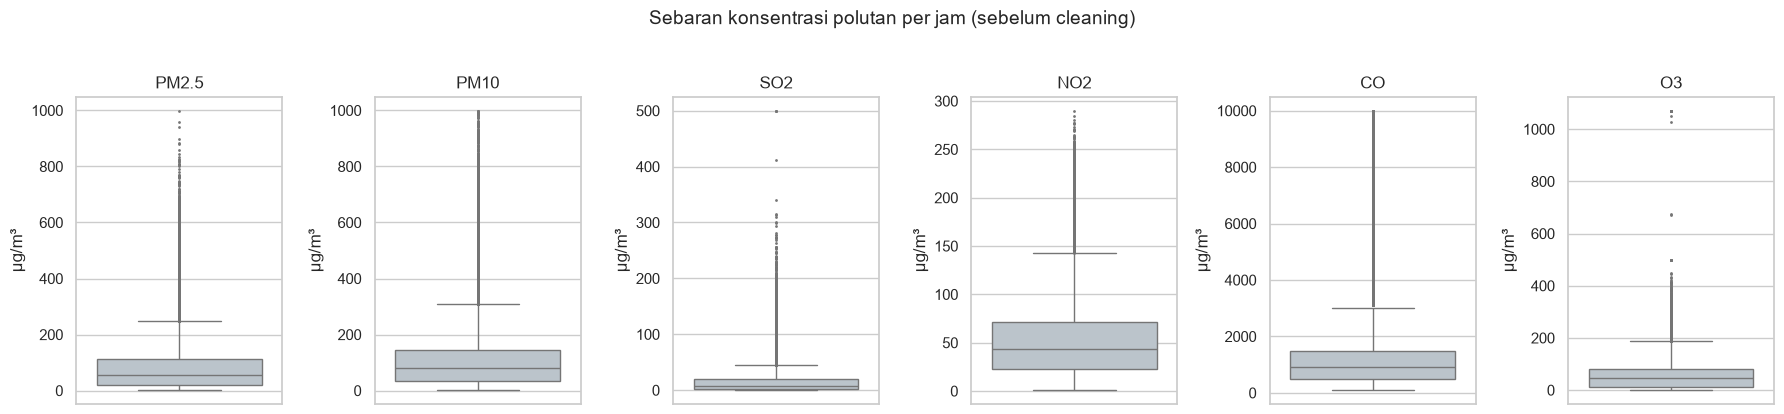

In [13]:
fig, axes = plt.subplots(1, len(pollutants), figsize=(18, 4))
for ax, col in zip(axes, pollutants):
    sns.boxplot(y=air_df[col], ax=ax, color=BASE, fliersize=1)
    ax.set_title(col)
    ax.set_ylabel("µg/m³")
fig.suptitle("Sebaran konsentrasi polutan per jam (sebelum cleaning)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

In [14]:
# Konsentrasi O3 > 500 µg/m³ per jam sangat tidak wajar untuk Beijing
# (rekor rata-rata per jam O3 di Beijing berada pada kisaran 300-400 µg/m³).
# Nilai 1071 yang berulang merupakan indikasi sensor jenuh / error.
suspicious_o3 = air_df[air_df["O3"] > 500]
print(f"Jumlah baris O3 > 500 µg/m³: {len(suspicious_o3)}")
suspicious_o3[["year", "month", "day", "hour", "station", "O3", "NO2", "PM2.5"]]

Jumlah baris O3 > 500 µg/m³: 18


,year,month,day,hour,station,O3,NO2,PM2.5
109223,2013,8,15,23,Dongsi,"1,071.00",40.00,195.00
109224,2013,8,16,0,Dongsi,"1,071.00",34.00,203.00
109226,2013,8,16,2,Dongsi,"1,050.00",19.00,64.00
109240,2013,8,16,16,Dongsi,"1,026.00",69.00,193.00
109241,2013,8,16,17,Dongsi,"1,071.00",65.00,206.00
109242,2013,8,16,18,Dongsi,"1,071.00",85.00,207.00
109243,2013,8,16,19,Dongsi,"1,071.00",86.00,187.00
109244,2013,8,16,20,Dongsi,"1,071.00",98.00,202.00
109245,2013,8,16,21,Dongsi,"1,071.00",95.00,202.00
109246,2013,8,16,22,Dongsi,"1,071.00",102.00,198.00


**Insight:**

| No | Masalah | Temuan | Rencana penanganan (Cleaning) |
|---|---|---|---|
| 1 | **Tipe data tidak tepat** | Waktu tersebar di 4 kolom integer (`year`, `month`, `day`, `hour`); kolom `No` hanya nomor urut | Gabungkan menjadi kolom `datetime`, hapus kolom `No` |
| 2 | **Missing value** | Terdapat di 12 kolom; terbanyak CO (20.701 baris / 4,92%), O3 (3,16%), NO2 (2,88%), SO2 (2,14%), PM2.5 (8.739 baris / 2,08%), `wd` (1.822 baris). Blok kosong terpanjang PM2.5 = 343 jam (Aotizhongxin) | Interpolasi berbasis waktu **per stasiun** untuk kolom numerik; *forward/backward fill* per stasiun untuk `wd` |
| 3 | **Invalid value** | **21.312 baris (5,07%)** memiliki PM2.5 > PM10, padahal PM2.5 adalah bagian dari PM10 | Ubah PM10 pada baris tersebut menjadi NaN → interpolasi → pastikan PM10 ≥ PM2.5 |
| 4 | **Inaccurate value** | **18 baris O3 > 500 µg/m³** (nilai 1.071 berulang selama ±30 jam di Dongsi, Agustus 2013) — indikasi sensor jenuh/error | Ubah menjadi NaN lalu interpolasi |
| 5 | **Outlier** | Outlier IQR ditemukan di seluruh polutan (PM2.5: 19.142 baris / 4,55%) dengan nilai maks 999 µg/m³ | **Dipertahankan**, karena lonjakan PM2.5 merupakan kejadian nyata (episode *haze* musim dingin Beijing) dan justru menjadi fokus analisis |
| 6 | Duplikasi & kelengkapan waktu | **0 duplikat** dan seluruh stasiun lengkap 35.064 jam | Tidak perlu penanganan |

### Cleaning Data

Langkah *cleaning* dilakukan sesuai temuan pada tahap Assessing Data:

1. Membuat kolom `datetime` dan menghapus kolom redundan `No`.
2. Mengganti nilai tidak akurat (O3 > 500 µg/m³) dan tidak valid (PM10 < PM2.5) menjadi `NaN` agar diisi ulang.
3. Mengisi *missing value* numerik dengan **interpolasi berbasis waktu per stasiun**, dan arah angin (`wd`) dengan *forward/backward fill* per stasiun.
4. Memastikan kembali konsistensi PM10 ≥ PM2.5.
5. Mempertahankan outlier PM2.5 yang wajar (episode *haze*), karena merupakan kejadian nyata yang justru penting untuk dianalisis.

#### 1. Membuat kolom datetime & menghapus kolom redundan

In [15]:
clean_df = air_df.copy()
clean_df["datetime"] = pd.to_datetime(clean_df[["year", "month", "day", "hour"]])
clean_df = (clean_df.drop(columns=["No"])
            .sort_values(["station", "datetime"])
            .reset_index(drop=True))
clean_df[["datetime", "station", "PM2.5"]].head()

,datetime,station,PM2.5
0,2013-03-01 00:00:00,Aotizhongxin,4.00
1,2013-03-01 01:00:00,Aotizhongxin,8.00
2,2013-03-01 02:00:00,Aotizhongxin,7.00
3,2013-03-01 03:00:00,Aotizhongxin,6.00
4,2013-03-01 04:00:00,Aotizhongxin,3.00


#### 2. Menandai nilai tidak akurat & tidak valid sebagai NaN

In [16]:
o3_mask = clean_df["O3"] > 500
pm_mask = clean_df["PM2.5"] > clean_df["PM10"]

clean_df.loc[o3_mask, "O3"] = np.nan
clean_df.loc[pm_mask, "PM10"] = np.nan
print(f"O3 tidak akurat yang di-NaN-kan   : {o3_mask.sum()}")
print(f"PM10 tidak valid yang di-NaN-kan  : {pm_mask.sum():,}")

O3 tidak akurat yang di-NaN-kan   : 18
PM10 tidak valid yang di-NaN-kan  : 21,312


#### 3. Mengisi missing value

- **Kolom numerik** diisi dengan `interpolate(method="time")` **di dalam setiap stasiun**, sehingga nilai yang hilang diestimasi dari jam sebelum dan sesudahnya di stasiun yang sama (polutan & cuaca bersifat kontinu dalam waktu). `limit_direction="both"` menangani NaN di awal/akhir deret.
- **Kolom `wd`** (kategorikal) diisi dengan nilai arah angin jam sebelumnya (`ffill`), lalu `bfill` untuk NaN di awal deret.

In [17]:
numeric_cols = pollutants + weather_cols

clean_df = clean_df.set_index("datetime")
clean_df[numeric_cols] = (clean_df.groupby("station")[numeric_cols]
                          .transform(lambda s: s.interpolate(method="time", limit_direction="both")))
clean_df["wd"] = clean_df.groupby("station")["wd"].transform(lambda s: s.ffill().bfill())
clean_df = clean_df.reset_index()

print("Sisa missing value:", int(clean_df.isna().sum().sum()))

Sisa missing value: 0


#### 4. Memastikan konsistensi PM10 ≥ PM2.5

In [18]:
# Interpolasi PM10 bisa saja masih menghasilkan nilai sedikit di bawah PM2.5,
# sehingga PM10 dibatasi minimal sama dengan PM2.5.
clean_df["PM10"] = clean_df[["PM10", "PM2.5"]].max(axis=1)
print("Baris PM2.5 > PM10 setelah cleaning:", (clean_df["PM2.5"] > clean_df["PM10"]).sum())
print("Nilai maksimum O3 setelah cleaning :", clean_df["O3"].max())

Baris PM2.5 > PM10 setelah cleaning: 0
Nilai maksimum O3 setelah cleaning : 500.0


#### 5. Feature engineering untuk kebutuhan analisis

- `tahun_pemantauan`: periode Maret–Februari (mis. `2013/14` = Mar 2013 – Feb 2014) agar setiap tahun berisi 12 bulan penuh dan musim dingin tidak terpotong.
- `musim`: Semi (Mar–Mei), Panas (Jun–Agu), Gugur (Sep–Nov), Dingin (Des–Feb).
- `wilayah`: pengelompokan manual stasiun menjadi **Pusat Kota** dan **Pinggiran Kota** berdasarkan lokasi geografisnya.

In [19]:
season_map = {12: "Dingin", 1: "Dingin", 2: "Dingin",
              3: "Semi", 4: "Semi", 5: "Semi",
              6: "Panas", 7: "Panas", 8: "Panas",
              9: "Gugur", 10: "Gugur", 11: "Gugur"}
season_order = ["Semi", "Panas", "Gugur", "Dingin"]

start_year = np.where(clean_df["month"] >= 3, clean_df["year"], clean_df["year"] - 1)
clean_df["tahun_pemantauan"] = [f"{y}/{str(y + 1)[-2:]}" for y in start_year]
clean_df["musim"] = pd.Categorical(clean_df["month"].map(season_map), categories=season_order, ordered=True)

suburban = ["Changping", "Dingling", "Huairou", "Shunyi"]
clean_df["wilayah"] = np.where(clean_df["station"].isin(suburban), "Pinggiran Kota", "Pusat Kota")

clean_df[["datetime", "station", "wilayah", "tahun_pemantauan", "musim", "PM2.5"]].sample(5, random_state=42)

,datetime,station,wilayah,tahun_pemantauan,musim,PM2.5
40688,2013-10-21 08:00:00,Changping,Pinggiran Kota,2013/14,Gugur,45.00
53199,2015-03-26 15:00:00,Changping,Pinggiran Kota,2015/16,Semi,82.00
103106,2016-12-04 02:00:00,Dingling,Pinggiran Kota,2016/17,Dingin,164.00
153700,2014-09-12 04:00:00,Guanyuan,Pusat Kota,2014/15,Gugur,97.00
141905,2013-05-08 17:00:00,Guanyuan,Pusat Kota,2013/14,Semi,119.00


In [20]:
# Menyimpan data bersih untuk dashboard
os.makedirs("dashboard", exist_ok=True)
main_cols = ["datetime", "station", "wilayah", "tahun_pemantauan", "musim", "year", "month", "hour",
             "PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"]
main_df = clean_df[main_cols].copy()
main_df[numeric_cols] = main_df[numeric_cols].round(1)
main_df.to_csv(os.path.join("dashboard", "main_data.csv"), index=False)
print("Data bersih tersimpan di dashboard/main_data.csv :", clean_df.shape)

Data bersih tersimpan di dashboard/main_data.csv : (420768, 21)


**Insight:**
- Kolom `datetime` berhasil dibuat dan kolom redundan `No` dihapus, sehingga data siap dianalisis secara deret waktu dan di-*resample* (harian/bulanan).
- **18 nilai O3 tidak akurat** dan **21.312 nilai PM10 tidak valid** telah dikoreksi. Setelah cleaning, **tidak ada lagi baris PM2.5 > PM10** dan nilai maksimum O3 menjadi 500 µg/m³ (wajar).
- Seluruh *missing value* (**0 tersisa**) telah ditangani dengan interpolasi waktu per stasiun, sehingga estimasi tidak tercampur antarstasiun. Karena porsi missing PM2.5 hanya ±2%, interpolasi tidak mengubah statistik secara berarti (rata-rata PM2.5 79,79 → 79,84 µg/m³).
- Outlier PM2.5 tetap dipertahankan karena mencerminkan episode polusi nyata.
- Ditambahkan fitur `tahun_pemantauan`, `musim`, dan `wilayah` (pengelompokan manual Pusat Kota vs Pinggiran Kota) untuk mendukung EDA. Data bersih disimpan sebagai `dashboard/main_data.csv` untuk digunakan dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif data bersih

In [21]:
clean_df[pollutants + weather_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,"420,768.00",79.84,80.95,2.00,20.00,55.00,111.00,999.00
PM10,"420,768.00",107.17,93.22,2.00,37.31,84.41,148.00,999.00
SO2,"420,768.00",15.91,21.90,0.29,3.00,7.00,20.00,500.00
NO2,"420,768.00",50.60,35.17,1.03,23.00,43.00,71.00,290.00
CO,"420,768.00","1,235.68","1,161.79",100.00,500.00,900.00,"1,500.00","10,000.00"
O3,"420,768.00",57.19,56.72,0.21,10.00,44.00,82.00,500.00
TEMP,"420,768.00",13.53,11.44,-19.90,3.10,14.50,23.30,41.60
PRES,"420,768.00","1,010.75",10.47,982.40,"1,002.30","1,010.40","1,019.00","1,042.80"
DEWP,"420,768.00",2.48,13.80,-43.40,-8.90,3.00,15.10,29.10
RAIN,"420,768.00",0.06,0.82,0.00,0.00,0.00,0.00,72.50


### Explore konsentrasi PM2.5 per stasiun (Pertanyaan 1)

Baku mutu PM2.5 China ditetapkan untuk **rata-rata 24 jam**, sehingga data per jam terlebih dahulu diagregasi menjadi **rata-rata harian per stasiun** sebelum dihitung jumlah hari yang melampaui 75 µg/m³.

In [22]:
daily_df = (clean_df.set_index("datetime")
            .groupby("station")[pollutants]
            .resample("D").mean()
            .reset_index())
daily_df["exceed"] = daily_df["PM2.5"] > PM25_STANDARD
print("Ukuran data harian:", daily_df.shape)
daily_df.head()

Ukuran data harian: (17532, 9)


,station,datetime,PM2.5,PM10,SO2,NO2,CO,O3,exceed
0,Aotizhongxin,2013-03-01,7.12,10.75,11.71,22.58,429.17,63.88,False
1,Aotizhongxin,2013-03-02,30.75,42.08,36.62,66.67,824.92,29.75,False
2,Aotizhongxin,2013-03-03,76.92,120.54,61.29,81.00,"1,620.62",19.12,True
3,Aotizhongxin,2013-03-04,22.71,44.58,22.85,46.19,606.25,53.75,False
4,Aotizhongxin,2013-03-05,148.88,183.79,93.88,132.83,"2,357.96",68.46,True


In [23]:
station_summary = (daily_df.groupby("station")
                   .agg(rata2_pm25=("PM2.5", "mean"),
                        median_pm25=("PM2.5", "median"),
                        maks_harian_pm25=("PM2.5", "max"),
                        hari_melampaui=("exceed", "sum"),
                        total_hari=("exceed", "count"))
                   .assign(persen_hari_melampaui=lambda d: d["hari_melampaui"] / d["total_hari"] * 100)
                   .sort_values("rata2_pm25", ascending=False))
station_summary

,rata2_pm25,median_pm25,maks_harian_pm25,hari_melampaui,total_hari,persen_hari_melampaui
station,,,,,,
Dongsi,86.14,66.12,567.42,636,1461,43.53
Nongzhanguan,85.08,63.29,516.06,625,1461,42.78
Wanshouxigong,85.07,64.62,536.62,626,1461,42.85
Gucheng,84.07,65.54,519.75,629,1461,43.05
Wanliu,83.47,64.62,481.29,626,1461,42.85
Guanyuan,82.90,63.83,536.08,616,1461,42.16
Aotizhongxin,82.54,62.46,512.29,614,1461,42.03
Tiantan,82.03,62.67,499.33,604,1461,41.34
Shunyi,79.44,60.04,514.62,596,1461,40.79


In [24]:
# Perbandingan pusat kota vs pinggiran kota
(clean_df.groupby("wilayah")
 .agg(jumlah_stasiun=("station", "nunique"), rata2_pm25=("PM2.5", "mean"),
      rata2_no2=("NO2", "mean"), rata2_co=("CO", "mean")))

,jumlah_stasiun,rata2_pm25,rata2_no2,rata2_co
wilayah,,,,
Pinggiran Kota,4,71.69,36.92,"1,074.92"
Pusat Kota,8,83.91,57.44,"1,316.06"


**Insight:**
- **Dongsi** mencatat rata-rata PM2.5 harian tertinggi (**86,1 µg/m³**) sekaligus persentase hari melampaui baku mutu terbesar (**43,5%** atau 636 dari 1.461 hari). Disusul Nongzhanguan (85,1) dan Wanshouxigong (85,1 µg/m³).
- **Dingling** adalah stasiun terbersih (66,8 µg/m³; 32,2% hari melampaui), diikuti Huairou dan Changping — ketiganya berada di pinggiran utara Beijing.
- Rata-rata PM2.5 **seluruh stasiun berada di atas 66 µg/m³**, dan 9 dari 12 stasiun memiliki rata-rata di atas baku mutu harian 75 µg/m³. Artinya, polusi PM2.5 adalah masalah seluruh kota, bukan hanya titik tertentu.
- Secara wilayah, rata-rata PM2.5 **Pusat Kota (83,9 µg/m³) ±17% lebih tinggi** daripada Pinggiran Kota (71,7 µg/m³). Pusat kota juga memiliki NO2 (57,4 vs 36,9 µg/m³) dan CO yang lebih tinggi — indikasi kuat kontribusi emisi lalu lintas kendaraan.

### Explore tren tahunan, pola musiman, dan pola harian PM2.5 (Pertanyaan 2)

In [25]:
yearly = (clean_df.groupby("tahun_pemantauan")["PM2.5"].mean().to_frame("rata2_pm25"))
yearly["perubahan_vs_tahun_lalu_%"] = yearly["rata2_pm25"].pct_change() * 100
yearly["perubahan_vs_2013/14_%"] = (yearly["rata2_pm25"] / yearly["rata2_pm25"].iloc[0] - 1) * 100

yearly_exceed = (daily_df.assign(tahun_pemantauan=lambda d: np.where(d["datetime"].dt.month >= 3,
                                                                      d["datetime"].dt.year,
                                                                      d["datetime"].dt.year - 1))
                 .assign(tahun_pemantauan=lambda d: d["tahun_pemantauan"].astype(str) + "/" +
                         (d["tahun_pemantauan"] + 1).astype(str).str[-2:])
                 .groupby("tahun_pemantauan")["exceed"].mean() * 100)
yearly["persen_hari_melampaui"] = yearly_exceed
yearly

,rata2_pm25,perubahan_vs_tahun_lalu_%,perubahan_vs_2013/14_%,persen_hari_melampaui
tahun_pemantauan,,,,
2013/14,87.03,NaN,0.00,45.46
2014/15,81.33,-6.55,-6.55,42.90
2015/16,72.88,-10.39,-16.26,34.29
2016/17,78.14,7.22,-10.22,38.77


In [26]:
seasonal = (clean_df.groupby("musim", observed=True)["PM2.5"]
            .agg(["mean", "median", "max"]).rename(columns=lambda c: f"{c}_pm25"))
seasonal

,mean_pm25,median_pm25,max_pm25
musim,,,
Semi,77.21,59.00,844.00
Panas,64.52,51.00,560.00
Gugur,82.21,55.00,687.00
Dingin,95.74,56.00,999.00


In [27]:
monthly = clean_df.groupby("month")["PM2.5"].mean().to_frame("rata2_pm25")
monthly.sort_values("rata2_pm25", ascending=False).head(5)

,rata2_pm25
month,
12,103.68
3,94.59
1,93.76
11,93.32
10,91.72


In [28]:
hourly = clean_df.groupby("hour")["PM2.5"].mean().to_frame("rata2_pm25")
print("Jam dengan rata-rata PM2.5 tertinggi:", hourly["rata2_pm25"].idxmax(),
      f"({hourly['rata2_pm25'].max():.1f} µg/m³)")
print("Jam dengan rata-rata PM2.5 terendah :", hourly["rata2_pm25"].idxmin(),
      f"({hourly['rata2_pm25'].min():.1f} µg/m³)")
hourly.T

Jam dengan rata-rata PM2.5 tertinggi: 22 (89.0 µg/m³)
Jam dengan rata-rata PM2.5 terendah : 7 (73.4 µg/m³)


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
rata2_pm25,87.70,86.85,84.80,82.21,79.47,76.54,74.29,73.42,74.40,76.06,77.13,77.14,76.55,76.05,75.46,74.56,74.40,75.52,78.01,82.50,86.64,88.81,89.03,88.60


In [29]:
# Pola harian per musim: apakah puncak malam hari konsisten di setiap musim?
clean_df.pivot_table(index="hour", columns="musim", values="PM2.5", aggfunc="mean", observed=True).iloc[::3]

musim,Semi,Panas,Gugur,Dingin
hour,,,,
0,79.19,64.71,92.29,115.17
3,76.97,63.38,82.73,106.23
6,74.62,62.85,71.18,88.74
9,81.24,68.60,72.27,82.20
12,79.99,66.75,77.70,81.87
15,74.52,63.10,79.72,81.08
18,71.42,61.76,84.70,94.57
21,79.46,65.31,96.02,115.05


**Insight:**
- **Tren tahunan:** rata-rata PM2.5 turun dari **87,0 µg/m³ (2013/14)** menjadi **72,9 µg/m³ (2015/16)** atau **turun 16,3%**, lalu **naik kembali 7,2%** menjadi 78,1 µg/m³ pada 2016/17. Secara keseluruhan, 2016/17 masih **10,2% lebih rendah** dibanding 2013/14. Persentase hari melampaui baku mutu juga turun dari 45,5% menjadi 38,8%.
- **Musiman:** **musim dingin (Des–Feb)** memiliki rata-rata PM2.5 tertinggi (**95,7 µg/m³**), sedangkan **musim panas (Jun–Agu)** terendah (**64,5 µg/m³**). Bulan dengan rata-rata tertinggi adalah **Desember (103,7 µg/m³)**, dan terendah Agustus.
- Median musim dingin (56 µg/m³) jauh lebih kecil daripada rata-ratanya (95,7) — menandakan distribusi sangat menceng kanan: musim dingin didominasi beberapa **episode haze ekstrem**, bukan polusi tinggi yang merata setiap hari.
- **Pola harian:** PM2.5 terendah pada **pukul 07.00 (73,4 µg/m³)** dan tertinggi pada **pukul 22.00 (89,0 µg/m³)**, dengan konsentrasi tinggi bertahan pukul 20.00–01.00. Pada musim dingin, rata-rata malam hari mencapai **±115 µg/m³**, jauh di atas siang hari (±81 µg/m³). Hal ini konsisten dengan penggunaan pemanas berbahan bakar batu bara di malam hari dan lapisan batas atmosfer (*boundary layer*) yang rendah sehingga polutan terperangkap.

### Explore hubungan kondisi angin dan PM2.5 (Pertanyaan 3)

Kecepatan angin dikelompokkan (*binning*) mengikuti pendekatan skala Beaufort yang disederhanakan agar mudah dipakai sebagai acuan operasional.

In [30]:
wind_bins = [-0.01, 1, 2, 3, 4, np.inf]
wind_labels = ["Tenang (≤1)", "Lemah (1–2]", "Sedang (2–3]", "Cukup kencang (3–4]", "Kencang (>4)"]
clean_df["kategori_angin"] = pd.cut(clean_df["WSPM"], bins=wind_bins, labels=wind_labels)

wind_speed_summary = (clean_df.groupby("kategori_angin", observed=True)["PM2.5"]
                      .agg(rata2_pm25="mean", median_pm25="median", jumlah_jam="count"))
wind_speed_summary["persen_jam"] = wind_speed_summary["jumlah_jam"] / len(clean_df) * 100
wind_speed_summary

,rata2_pm25,median_pm25,jumlah_jam,persen_jam
kategori_angin,,,,
Tenang (≤1),101.90,76.00,135360,32.17
Lemah (1–2],84.64,61.00,164849,39.18
Sedang (2–3],59.39,39.00,65814,15.64
Cukup kencang (3–4],41.16,20.00,29588,7.03
Kencang (>4),28.73,13.00,25157,5.98


In [31]:
calm = wind_speed_summary.loc["Tenang (≤1)", "rata2_pm25"]
strong = wind_speed_summary.loc["Kencang (>4)", "rata2_pm25"]
print(f"Selisih PM2.5 angin tenang vs kencang: {calm - strong:.1f} µg/m³ "
      f"(angin tenang {calm / strong:.1f}x lebih tinggi; angin kencang {1 - strong / calm:.0%} lebih rendah)")

Selisih PM2.5 angin tenang vs kencang: 73.2 µg/m³ (angin tenang 3.5x lebih tinggi; angin kencang 72% lebih rendah)


In [32]:
compass = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
           "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
wind_dir_summary = (clean_df.groupby("wd")
                    .agg(rata2_pm25=("PM2.5", "mean"), rata2_wspm=("WSPM", "mean"), jumlah_jam=("PM2.5", "count"))
                    .reindex(compass))
wind_dir_summary.sort_values("rata2_pm25", ascending=False)

,rata2_pm25,rata2_wspm,jumlah_jam
wd,,,
ESE,101.98,1.54,24264
E,101.67,1.31,29822
ENE,97.72,1.34,34215
SE,96.67,1.52,20211
SSE,93.44,1.67,17741
S,89.31,1.73,19444
NE,86.19,1.40,43653
SSW,84.14,1.83,22606
SW,79.54,1.94,28998


In [33]:
# Korelasi PM2.5 dengan polutan lain dan variabel cuaca
clean_df[pollutants + weather_cols].corr()["PM2.5"].drop("PM2.5").sort_values().to_frame("korelasi_dengan_PM2.5")

,korelasi_dengan_PM2.5
WSPM,-0.27
O3,-0.15
TEMP,-0.13
RAIN,-0.01
PRES,0.02
DEWP,0.11
SO2,0.48
NO2,0.66
CO,0.78
PM10,0.89


**Insight:**
- Terdapat hubungan terbalik yang jelas antara kecepatan angin dan PM2.5: rata-rata PM2.5 saat **angin tenang (≤ 1 m/s) = 101,9 µg/m³**, sedangkan saat **angin kencang (> 4 m/s) = 28,7 µg/m³**. Selisihnya **73,2 µg/m³** — PM2.5 saat angin kencang **72% lebih rendah** (angin tenang ±3,5× lebih tercemar).
- Kondisi angin tenang cukup sering terjadi, yaitu **32% dari seluruh jam pengukuran**, dan hanya kategori angin ≤ 2 m/s yang rata-ratanya melampaui baku mutu.
- **Arah angin:** angin dari **timur–tenggara (E, ESE, ENE, SE)** berasosiasi dengan PM2.5 tertinggi (**±97–102 µg/m³**), sedangkan angin dari **barat laut (NW, NNW, WNW)** berasosiasi dengan PM2.5 terendah (**±52–57 µg/m³**). Angin barat laut juga merupakan angin dengan kecepatan rata-rata tertinggi (±2,1–2,5 m/s), membawa udara bersih dari pegunungan/Mongolia.
- Korelasi PM2.5 dengan `WSPM` bernilai **−0,27** (variabel cuaca dengan korelasi terkuat). Korelasi tinggi PM2.5 dengan PM10 (0,89), CO (0,78), dan NO2 (0,66) menunjukkan sumber emisi pembakaran yang sama (kendaraan, industri, pemanas).

## Visualization & Explanatory Analysis

Seluruh visualisasi dirancang mengikuti prinsip desain dan integritas data: judul yang menyampaikan pesan utama, label sumbu beserta satuan, sumbu batang dimulai dari nol, warna sorotan hanya untuk informasi terpenting, dan garis acuan baku mutu sebagai konteks.

### Pertanyaan 1: Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan persentase hari melampaui baku mutu terbesar (Mar 2013 – Feb 2017)?

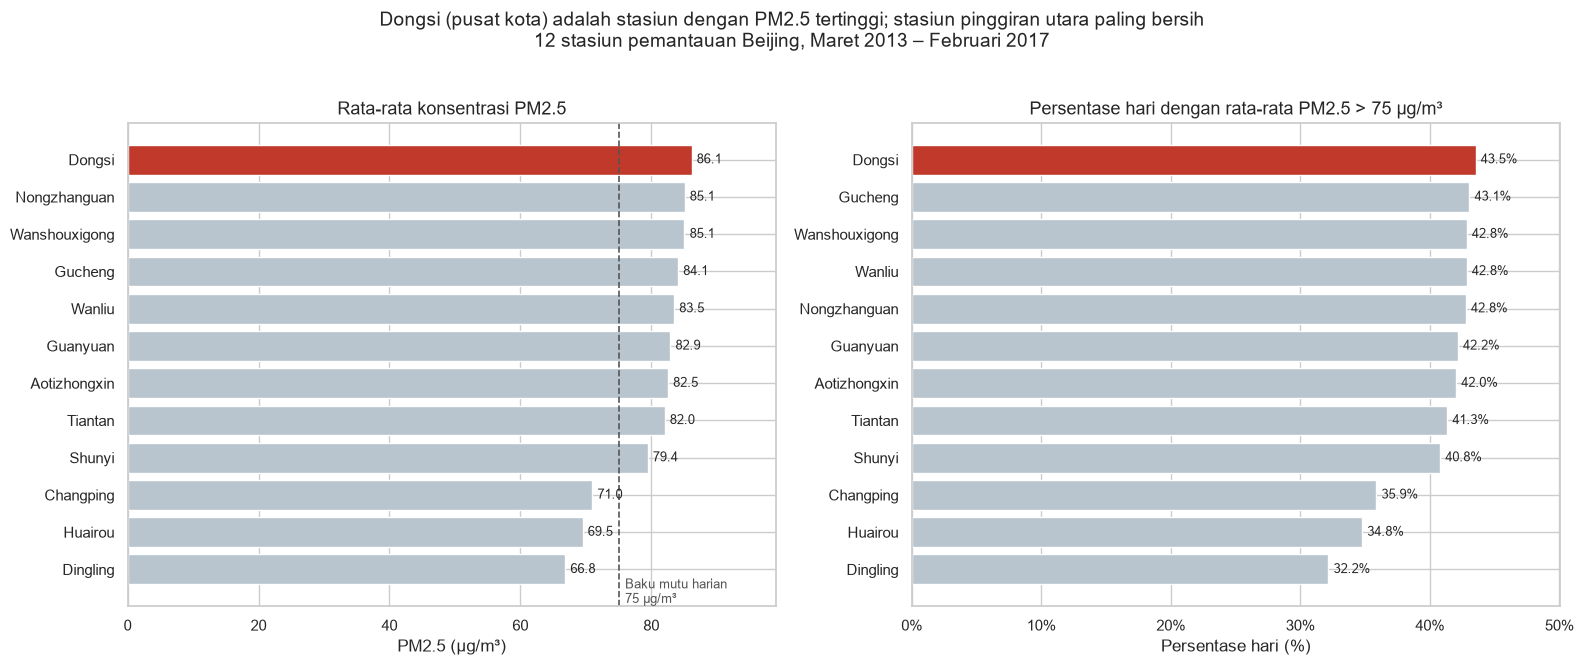

In [34]:
plot_df = station_summary.sort_values("rata2_pm25")
colors_mean = [HIGHLIGHT if s == plot_df["rata2_pm25"].idxmax() else BASE for s in plot_df.index]
plot_df_ex = station_summary.sort_values("persen_hari_melampaui")
colors_ex = [HIGHLIGHT if s == plot_df_ex["persen_hari_melampaui"].idxmax() else BASE for s in plot_df_ex.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

axes[0].barh(plot_df.index, plot_df["rata2_pm25"], color=colors_mean)
axes[0].axvline(PM25_STANDARD, color="#555555", ls="--", lw=1.2)
axes[0].text(PM25_STANDARD + 1, -0.9, f"Baku mutu harian\n{PM25_STANDARD} µg/m³", fontsize=9, color="#555555")
for i, v in enumerate(plot_df["rata2_pm25"]):
    axes[0].text(v + 0.8, i, f"{v:.1f}", va="center", fontsize=9)
axes[0].set_title("Rata-rata konsentrasi PM2.5", fontsize=13)
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].set_ylabel(None)
axes[0].set_xlim(0, plot_df["rata2_pm25"].max() * 1.15)

axes[1].barh(plot_df_ex.index, plot_df_ex["persen_hari_melampaui"], color=colors_ex)
for i, v in enumerate(plot_df_ex["persen_hari_melampaui"]):
    axes[1].text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
axes[1].set_title(f"Persentase hari dengan rata-rata PM2.5 > {PM25_STANDARD} µg/m³", fontsize=13)
axes[1].set_xlabel("Persentase hari (%)")
axes[1].set_ylabel(None)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_xlim(0, plot_df_ex["persen_hari_melampaui"].max() * 1.15)

fig.suptitle("Dongsi (pusat kota) adalah stasiun dengan PM2.5 tertinggi; stasiun pinggiran utara paling bersih\n"
             "12 stasiun pemantauan Beijing, Maret 2013 – Februari 2017", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Insight:**
- Visualisasi menegaskan bahwa **Dongsi** (stasiun pusat kota, distrik Dongcheng) merupakan stasiun dengan **rata-rata PM2.5 tertinggi (86,1 µg/m³)** dan **persentase hari melampaui baku mutu terbesar (43,5%)** — sehingga menjadi prioritas utama intervensi.
- Perbedaan antar 8 stasiun pusat kota relatif kecil (82,0–86,1 µg/m³; 41–44% hari melampaui), sedangkan 3 stasiun pinggiran utara (Changping, Huairou, Dingling) tampak jelas lebih rendah (66,8–71,0 µg/m³; 32–36%). Artinya intervensi sebaiknya menyasar **kawasan pusat kota secara keseluruhan**, dengan Dongsi sebagai titik pertama.
- Garis baku mutu memperlihatkan bahwa **9 dari 12 stasiun memiliki rata-rata jangka panjang di atas 75 µg/m³**.

### Pertanyaan 2: Bagaimana tren tahunan serta pada musim, bulan, dan jam apa PM2.5 mencapai puncaknya (2013/14 – 2016/17)?

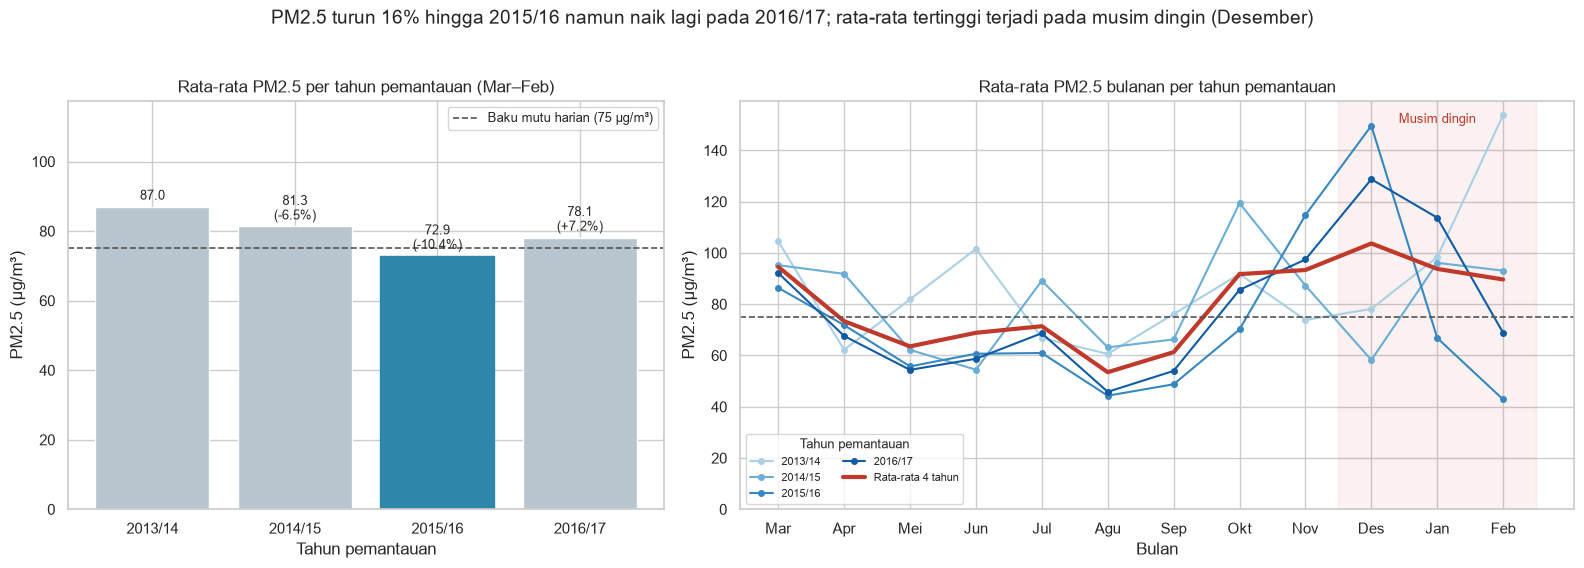

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})

# (a) Tren tahunan
ax = axes[0]
bars = ax.bar(yearly.index, yearly["rata2_pm25"], color=BASE)
best_idx = yearly["rata2_pm25"].values.argmin()
bars[best_idx].set_color(ACCENT)
ax.axhline(PM25_STANDARD, color="#555555", ls="--", lw=1.2, label=f"Baku mutu harian ({PM25_STANDARD} µg/m³)")
for i, (v, chg) in enumerate(zip(yearly["rata2_pm25"], yearly["perubahan_vs_tahun_lalu_%"])):
    label = f"{v:.1f}" if np.isnan(chg) else f"{v:.1f}\n({chg:+.1f}%)"
    ax.text(i, v + 2, label, ha="center", fontsize=9)
ax.set_ylim(0, yearly["rata2_pm25"].max() * 1.35)
ax.legend(loc="upper right", fontsize=9)
ax.set_title("Rata-rata PM2.5 per tahun pemantauan (Mar–Feb)", fontsize=12)
ax.set_xlabel("Tahun pemantauan")
ax.set_ylabel("PM2.5 (µg/m³)")

# (b) Pola bulanan per tahun pemantauan
ax = axes[1]
month_order = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 1, 2]
month_names = ["Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des", "Jan", "Feb"]
monthly_year = (clean_df.pivot_table(index="month", columns="tahun_pemantauan", values="PM2.5", aggfunc="mean")
                .reindex(month_order))
palette = sns.color_palette("Blues", n_colors=len(monthly_year.columns) + 1)[1:]
for color, col in zip(palette, monthly_year.columns):
    ax.plot(month_names, monthly_year[col], marker="o", ms=4, lw=1.5, color=color, label=col)
ax.plot(month_names, monthly_year.mean(axis=1), color=HIGHLIGHT, lw=3, label="Rata-rata 4 tahun")
ax.axhline(PM25_STANDARD, color="#555555", ls="--", lw=1.2)
ax.axvspan(8.5, 11.5, color=HIGHLIGHT, alpha=0.07)
ax.text(10, ax.get_ylim()[1] * 0.97, "Musim dingin", ha="center", va="top", fontsize=9, color=HIGHLIGHT)
ax.set_ylim(0, None)
ax.set_title("Rata-rata PM2.5 bulanan per tahun pemantauan", fontsize=12)
ax.set_xlabel("Bulan")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend(title="Tahun pemantauan", fontsize=8, title_fontsize=9, ncol=2, loc="lower left")

fig.suptitle("PM2.5 turun 16% hingga 2015/16 namun naik lagi pada 2016/17; rata-rata tertinggi terjadi pada musim dingin (Desember)",
             fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

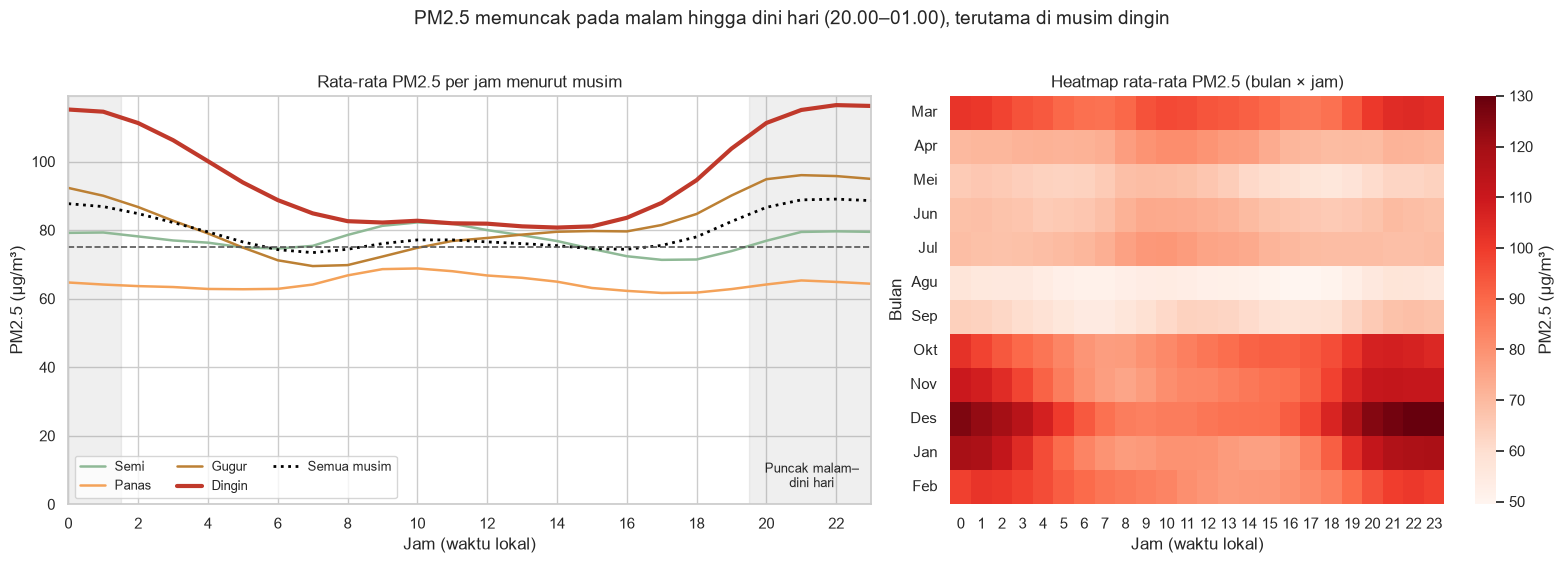

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

# (c) Pola harian per musim
ax = axes[0]
hourly_season = clean_df.pivot_table(index="hour", columns="musim", values="PM2.5", aggfunc="mean", observed=True)
season_colors = {"Semi": "#8FB996", "Panas": "#F4A259", "Gugur": "#BC8034", "Dingin": HIGHLIGHT}
for s in season_order:
    ax.plot(hourly_season.index, hourly_season[s], lw=3 if s == "Dingin" else 1.8,
            color=season_colors[s], label=s)
ax.plot(hourly.index, hourly["rata2_pm25"], color="black", ls=":", lw=2, label="Semua musim")
ax.axhline(PM25_STANDARD, color="#555555", ls="--", lw=1.2)
ax.axvspan(19.5, 23, color="grey", alpha=0.12)
ax.axvspan(0, 1.5, color="grey", alpha=0.12)
ax.text(21.3, 5, "Puncak malam–\ndini hari", ha="center", fontsize=9)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(0, 23)
ax.set_ylim(0, None)
ax.set_title("Rata-rata PM2.5 per jam menurut musim", fontsize=12)
ax.set_xlabel("Jam (waktu lokal)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend(fontsize=9, ncol=3, loc="lower left")

# (d) Heatmap bulan x jam
ax = axes[1]
heat = clean_df.pivot_table(index="month", columns="hour", values="PM2.5", aggfunc="mean").reindex(month_order)
sns.heatmap(heat, cmap="Reds", ax=ax, cbar_kws={"label": "PM2.5 (µg/m³)"})
ax.set_yticklabels(month_names, rotation=0)
ax.set_title("Heatmap rata-rata PM2.5 (bulan × jam)", fontsize=12)
ax.set_xlabel("Jam (waktu lokal)")
ax.set_ylabel("Bulan")

fig.suptitle("PM2.5 memuncak pada malam hingga dini hari (20.00–01.00), terutama di musim dingin", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Insight:**
- Grafik tren tahunan memperlihatkan **penurunan PM2.5 sebesar 6,5% (2014/15) dan 10,4% (2015/16)** berturut-turut, sejalan dengan implementasi *Action Plan*. Namun pada **2016/17 terjadi kenaikan 7,2%**, terutama karena episode haze besar pada **Desember 2016 dan Januari 2017** (garis 2016/17 melonjak di bulan-bulan tersebut).
- Pola bulanan membentuk kurva "U": rendah di musim panas (minimum Agustus) dan tinggi di akhir musim gugur hingga musim dingin (puncak rata-rata **Desember, 103,7 µg/m³**). Variasi antar tahun sangat besar di musim dingin, menunjukkan ketergantungan pada kondisi meteorologi.
- Pola harian & heatmap memperlihatkan **puncak PM2.5 pukul 20.00–01.00** dan titik terendah sekitar pukul 07.00 serta 15.00–17.00. Kombinasi **bulan Oktober–Januari × jam 19.00–02.00** merupakan zona paling berisiko (warna paling gelap pada heatmap), dengan rata-rata musim dingin malam hari ±115 µg/m³.

### Pertanyaan 3: Seberapa besar pengaruh kecepatan dan arah angin terhadap PM2.5 (Mar 2013 – Feb 2017)?

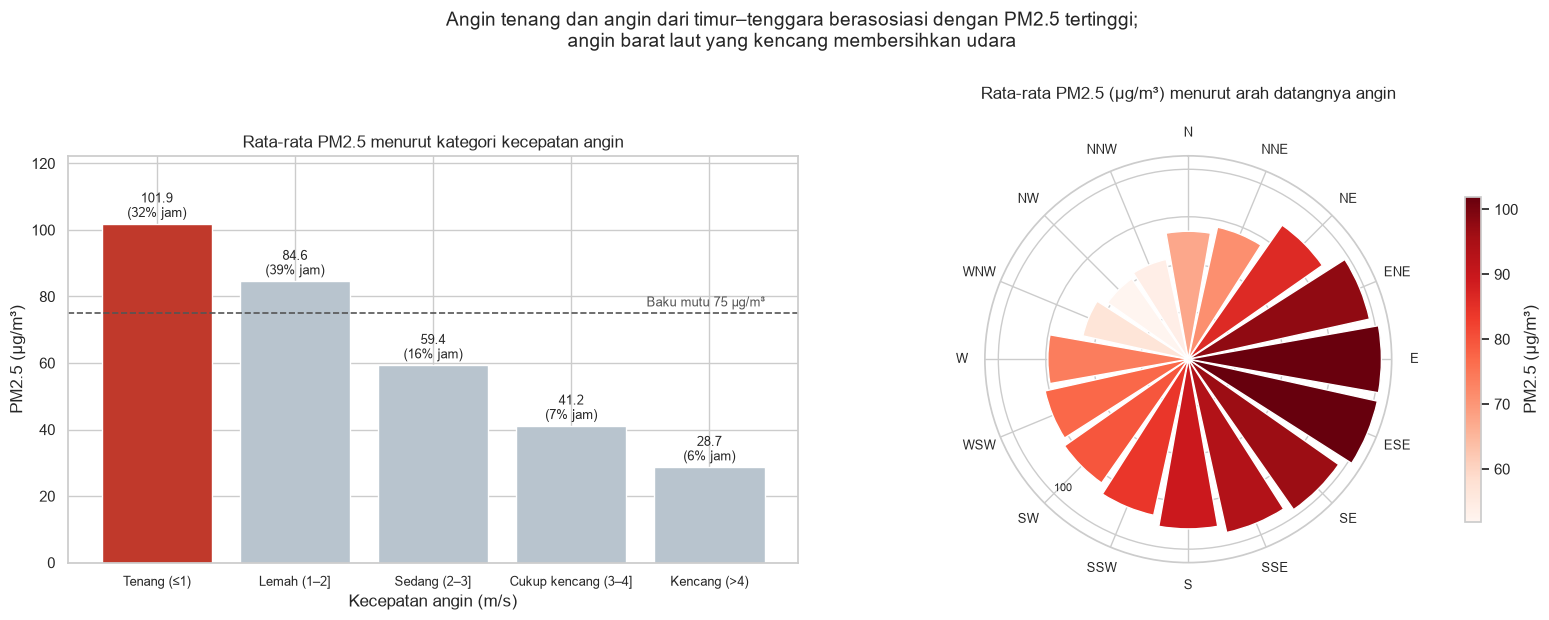

In [37]:
fig = plt.figure(figsize=(16, 6))

# (a) Kecepatan angin
ax1 = fig.add_subplot(1, 2, 1)
ws = wind_speed_summary.reset_index()
colors_ws = [HIGHLIGHT if i == 0 else BASE for i in range(len(ws))]
ax1.bar(ws["kategori_angin"].astype(str), ws["rata2_pm25"], color=colors_ws)
ax1.axhline(PM25_STANDARD, color="#555555", ls="--", lw=1.2)
ax1.text(4.4, PM25_STANDARD + 2, f"Baku mutu {PM25_STANDARD} µg/m³", ha="right", fontsize=9, color="#555555")
for i, (v, p) in enumerate(zip(ws["rata2_pm25"], ws["persen_jam"])):
    ax1.text(i, v + 2, f"{v:.1f}\n({p:.0f}% jam)", ha="center", fontsize=9)
ax1.set_ylim(0, ws["rata2_pm25"].max() * 1.2)
ax1.set_title("Rata-rata PM2.5 menurut kategori kecepatan angin", fontsize=12)
ax1.set_xlabel("Kecepatan angin (m/s)")
ax1.set_ylabel("PM2.5 (µg/m³)")
ax1.tick_params(axis="x", labelsize=9)

# (b) Arah angin (polar bar / "pollution rose")
ax2 = fig.add_subplot(1, 2, 2, projection="polar")
theta = np.deg2rad(np.arange(0, 360, 22.5))
values = wind_dir_summary["rata2_pm25"].values
norm = plt.Normalize(values.min(), values.max())
ax2.bar(theta, values, width=np.deg2rad(20), color=plt.cm.Reds(norm(values)), edgecolor="white")
ax2.set_theta_zero_location("N")
ax2.set_theta_direction(-1)
ax2.set_xticks(theta)
ax2.set_xticklabels(compass, fontsize=9)
ax2.set_rlabel_position(225)
ax2.set_yticks([25, 50, 75, 100])
ax2.tick_params(axis="y", labelsize=8)
ax2.set_title("Rata-rata PM2.5 (µg/m³) menurut arah datangnya angin", fontsize=12, pad=20)
sm = plt.cm.ScalarMappable(cmap="Reds", norm=norm)
fig.colorbar(sm, ax=ax2, pad=0.1, shrink=0.8, label="PM2.5 (µg/m³)")

fig.suptitle("Angin tenang dan angin dari timur–tenggara berasosiasi dengan PM2.5 tertinggi;\n"
             "angin barat laut yang kencang membersihkan udara", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
- Grafik batang menunjukkan penurunan PM2.5 yang **konsisten (monoton)** seiring bertambahnya kecepatan angin: dari **101,9 µg/m³ (tenang)** menjadi **28,7 µg/m³ (kencang)**. Hanya kondisi angin ≤ 2 m/s (71% dari seluruh jam) yang rata-ratanya melampaui baku mutu.
- *Pollution rose* memperlihatkan asimetri yang jelas: sisi **timur–tenggara–selatan** berwarna gelap (PM2.5 ±89–102 µg/m³), sedangkan sisi **barat laut** paling terang (±52–57 µg/m³). Angin dari arah timur/selatan membawa polutan dari kawasan industri dataran Hebei–Tianjin dan terperangkap oleh pegunungan di barat & utara Beijing, sedangkan angin barat laut membawa udara bersih.
- Dengan demikian, **prakiraan "angin tenang" atau "angin dari timur–selatan"** dapat dijadikan **indikator dini** datangnya episode polusi tinggi.

## Analisis Lanjutan (Opsional)

### 1. Geospatial Analysis – Peta sebaran PM2.5 antar stasiun

**Tujuan:** Memetakan lokasi ke-12 stasiun pemantauan untuk melihat **pola spasial** polusi PM2.5 di Beijing — apakah konsentrasi tinggi mengelompok di wilayah tertentu (mis. pusat kota) — sehingga intervensi dapat difokuskan secara geografis. Peta dibuat dengan **folium**: ukuran lingkaran menunjukkan rata-rata PM2.5, sedangkan warna menunjukkan persentase hari melampaui baku mutu.

Koordinat stasiun diambil dari lokasi stasiun pemantauan resmi Beijing Municipal Environmental Monitoring Center (perkiraan).

In [38]:
station_coords = pd.DataFrame({
    "station": ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng",
                "Huairou", "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"],
    "lat": [39.982, 40.217, 40.292, 39.929, 39.929, 39.914, 40.328, 39.937, 40.127, 39.886, 39.987, 39.878],
    "lon": [116.397, 116.230, 116.220, 116.417, 116.339, 116.184, 116.628, 116.461, 116.655, 116.407, 116.287, 116.352],
})
geo_df = station_coords.merge(station_summary.reset_index(), on="station")
geo_df["wilayah"] = np.where(geo_df["station"].isin(suburban), "Pinggiran Kota", "Pusat Kota")
geo_df[["station", "wilayah", "lat", "lon", "rata2_pm25", "persen_hari_melampaui"]].sort_values("rata2_pm25", ascending=False)

,station,wilayah,lat,lon,rata2_pm25,persen_hari_melampaui
3,Dongsi,Pusat Kota,39.93,116.42,86.14,43.53
7,Nongzhanguan,Pusat Kota,39.94,116.46,85.08,42.78
11,Wanshouxigong,Pusat Kota,39.88,116.35,85.07,42.85
5,Gucheng,Pusat Kota,39.91,116.18,84.07,43.05
10,Wanliu,Pusat Kota,39.99,116.29,83.47,42.85
4,Guanyuan,Pusat Kota,39.93,116.34,82.90,42.16
0,Aotizhongxin,Pusat Kota,39.98,116.40,82.54,42.03
9,Tiantan,Pusat Kota,39.89,116.41,82.03,41.34
8,Shunyi,Pinggiran Kota,40.13,116.66,79.44,40.79
1,Changping,Pinggiran Kota,40.22,116.23,70.99,35.87


In [39]:
colormap = cm.LinearColormap(["#FDD49E", "#FC8D59", "#B30000"],
                             vmin=geo_df["persen_hari_melampaui"].min(),
                             vmax=geo_df["persen_hari_melampaui"].max(),
                             caption=f"% hari dengan rata-rata PM2.5 > {PM25_STANDARD} µg/m³")

beijing_map = folium.Map(location=[40.07, 116.40], zoom_start=10, tiles="OpenStreetMap")
for _, r in geo_df.iterrows():
    folium.CircleMarker(
        location=[r["lat"], r["lon"]],
        radius=(r["rata2_pm25"] - 55) * 0.9,
        color=colormap(r["persen_hari_melampaui"]),
        fill=True, fill_opacity=0.8, weight=1,
        tooltip=f"{r['station']} ({r['wilayah']})",
        popup=folium.Popup(
            f"<b>{r['station']}</b><br>Wilayah: {r['wilayah']}<br>"
            f"Rata-rata PM2.5: {r['rata2_pm25']:.1f} µg/m³<br>"
            f"Hari > {PM25_STANDARD} µg/m³: {r['persen_hari_melampaui']:.1f}%", max_width=250),
    ).add_to(beijing_map)
    folium.map.Marker(
        [r["lat"], r["lon"]],
        icon=folium.DivIcon(html=f"<div style='font-size:10px;font-weight:bold;margin-left:14px;'>{r['station']}</div>"),
    ).add_to(beijing_map)
colormap.add_to(beijing_map)
beijing_map

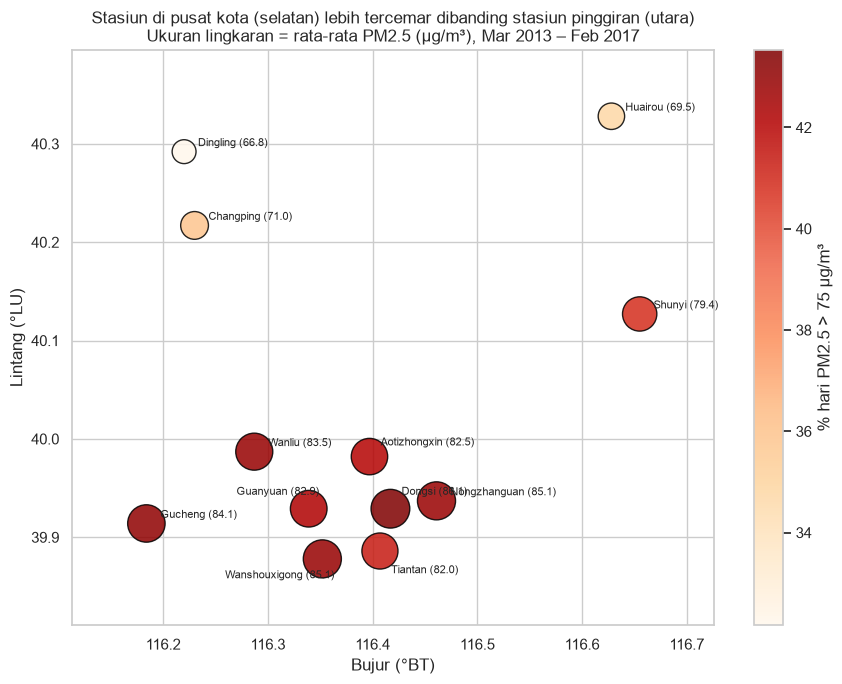

In [40]:
# Versi statis (agar tetap terlihat bila peta interaktif tidak ter-render, mis. di GitHub)
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(geo_df["lon"], geo_df["lat"], s=(geo_df["rata2_pm25"] - 55) * 25,
                c=geo_df["persen_hari_melampaui"], cmap="OrRd", edgecolor="black", alpha=0.85)
label_offset = {"Dongsi": (8, 10), "Tiantan": (8, -16), "Wanshouxigong": (-70, -14),
                "Nongzhanguan": (10, 4), "Guanyuan": (-52, 10), "Aotizhongxin": (8, 8)}
for _, r in geo_df.iterrows():
    ax.annotate(f"{r['station']} ({r['rata2_pm25']:.1f})", (r["lon"], r["lat"]),
                xytext=label_offset.get(r["station"], (10, 4)), textcoords="offset points", fontsize=8)
plt.colorbar(sc, ax=ax, label=f"% hari PM2.5 > {PM25_STANDARD} µg/m³")
ax.set_xlabel("Bujur (°BT)")
ax.set_ylabel("Lintang (°LU)")
ax.set_title("Stasiun di pusat kota (selatan) lebih tercemar dibanding stasiun pinggiran (utara)\n"
             "Ukuran lingkaran = rata-rata PM2.5 (µg/m³), Mar 2013 – Feb 2017", fontsize=12)
ax.margins(0.15)
plt.tight_layout()
plt.show()

**Insight:**
- Peta memperlihatkan **pola spasial yang jelas**: stasiun dengan PM2.5 tinggi (lingkaran besar, warna merah tua) **mengelompok di pusat kota bagian selatan** (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, Tiantan, Guanyuan), sedangkan stasiun di **pinggiran utara** (Dingling, Changping, Huairou) memiliki PM2.5 lebih rendah.
- Terdapat **gradien selatan → utara**: semakin ke utara (mendekati pegunungan Yanshan), konsentrasi PM2.5 semakin rendah. Ini sejalan dengan temuan Pertanyaan 3 bahwa polutan banyak terbawa angin dari selatan/timur dan dibersihkan oleh angin barat laut.
- **Shunyi** (timur laut) menjadi pengecualian: meski berada di pinggiran, PM2.5-nya (79,4 µg/m³) mendekati stasiun pusat kota — kemungkinan karena kedekatannya dengan Bandara Internasional Beijing dan kawasan industri di timur. Stasiun ini perlu diperhatikan meski berada di luar pusat kota.

### 2. Clustering (Binning) – Kategori kualitas udara harian

**Tujuan:** Mengelompokkan setiap hari di setiap stasiun ke dalam **kategori kualitas udara** berdasarkan rata-rata PM2.5 harian, **tanpa algoritma machine learning**, menggunakan teknik *binning* (`pd.cut`) dengan batas kategori mengikuti standar **Air Quality Index (AQI) China – HJ 633-2012** untuk PM2.5 24 jam. Hasilnya lebih mudah dipahami publik dan pembuat kebijakan dibandingkan angka konsentrasi mentah.

| Kategori | Rentang PM2.5 harian (µg/m³) |
|---|---|
| Baik | 0 – 35 |
| Sedang | > 35 – 75 |
| Tidak Sehat (Sensitif) | > 75 – 115 |
| Tidak Sehat | > 115 – 150 |
| Sangat Tidak Sehat | > 150 – 250 |
| Berbahaya | > 250 |

In [41]:
aqi_bins = [0, 35, 75, 115, 150, 250, np.inf]
aqi_labels = ["Baik", "Sedang", "Tidak Sehat (Sensitif)", "Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"]
aqi_colors = ["#00A65A", "#F2C80F", "#F39C12", "#E74C3C", "#8E44AD", "#7B241C"]

daily_df["kategori_aqi"] = pd.cut(daily_df["PM2.5"], bins=aqi_bins, labels=aqi_labels, include_lowest=True)
daily_df["musim"] = pd.Categorical(daily_df["datetime"].dt.month.map(season_map), categories=season_order, ordered=True)

aqi_overall = daily_df["kategori_aqi"].value_counts(normalize=True).reindex(aqi_labels) * 100
aqi_overall.to_frame("persen_hari")

,persen_hari
kategori_aqi,
Baik,29.55
Sedang,30.10
Tidak Sehat (Sensitif),18.24
Tidak Sehat,9.49
Sangat Tidak Sehat,9.19
Berbahaya,3.42


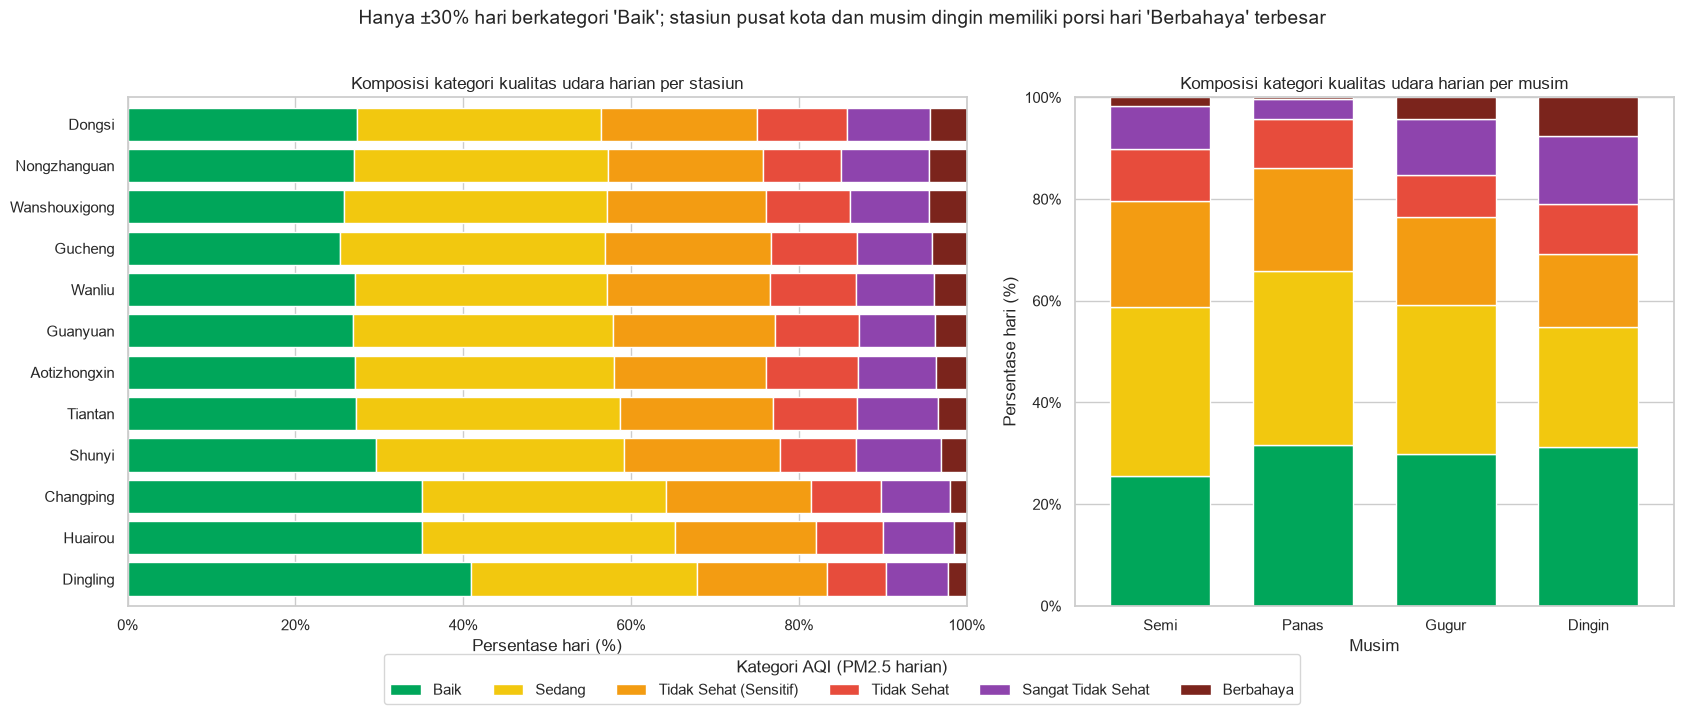

In [42]:
aqi_station = (pd.crosstab(daily_df["station"], daily_df["kategori_aqi"], normalize="index") * 100)
aqi_station = aqi_station.loc[station_summary.index[::-1]]  # urut dari PM2.5 terendah ke tertinggi
aqi_season = pd.crosstab(daily_df["musim"], daily_df["kategori_aqi"], normalize="index") * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
aqi_station.plot(kind="barh", stacked=True, color=aqi_colors, ax=axes[0], width=0.8, legend=False)
axes[0].set_title("Komposisi kategori kualitas udara harian per stasiun", fontsize=12)
axes[0].set_xlabel("Persentase hari (%)")
axes[0].set_ylabel(None)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_xlim(0, 100)

aqi_season.plot(kind="bar", stacked=True, color=aqi_colors, ax=axes[1], width=0.7, legend=False, rot=0)
axes[1].set_title("Komposisi kategori kualitas udara harian per musim", fontsize=12)
axes[1].set_ylabel("Persentase hari (%)")
axes[1].set_xlabel("Musim")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_ylim(0, 100)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.06), title="Kategori AQI (PM2.5 harian)")
fig.suptitle("Hanya ±30% hari berkategori 'Baik'; stasiun pusat kota dan musim dingin memiliki porsi hari 'Berbahaya' terbesar",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [43]:
# Persentase hari per kategori AQI di setiap musim
aqi_season.round(1)

kategori_aqi,Baik,Sedang,Tidak Sehat (Sensitif),Tidak Sehat,Sangat Tidak Sehat,Berbahaya
musim,,,,,,
Semi,25.60,33.20,20.90,10.10,8.40,1.70
Panas,31.60,34.20,20.20,9.70,4.10,0.20
Gugur,29.80,29.30,17.30,8.30,11.00,4.30
Dingin,31.30,23.50,14.50,9.90,13.30,7.50


In [44]:
# Manual grouping: perbandingan kategori AQI antara pusat kota dan pinggiran kota
daily_df["wilayah"] = np.where(daily_df["station"].isin(suburban), "Pinggiran Kota", "Pusat Kota")
(pd.crosstab(daily_df["wilayah"], daily_df["kategori_aqi"], normalize="index") * 100).round(1)

kategori_aqi,Baik,Sedang,Tidak Sehat (Sensitif),Tidak Sehat,Sangat Tidak Sehat,Berbahaya
wilayah,,,,,,
Pinggiran Kota,35.20,28.90,17.00,8.10,8.50,2.20
Pusat Kota,26.70,30.70,18.90,10.20,9.50,4.00


**Insight:**
- Secara keseluruhan (12 stasiun × 1.461 hari), hanya **29,6% hari berkategori "Baik"**, 30,1% "Sedang", dan **±40% hari berada pada kategori tidak sehat atau lebih buruk**, termasuk **3,4% hari "Berbahaya"** (PM2.5 harian > 250 µg/m³).
- **Per stasiun:** Dingling memiliki porsi hari "Baik" terbesar (±41%), sedangkan stasiun pusat kota seperti Gucheng dan Wanshouxigong hanya ±26%. Porsi hari "Berbahaya" di stasiun pusat kota (±4–5%) sekitar 2× lipat stasiun pinggiran utara.
- **Per musim:** musim dingin bersifat "terpolarisasi" — porsi hari "Baik"-nya relatif tinggi (±31%, saat angin barat laut kencang bertiup) tetapi juga memiliki **porsi "Berbahaya" terbesar (±8%)** dan "Sangat Tidak Sehat" ±13%. Musim panas hampir tidak memiliki hari "Berbahaya".
- **Manual grouping wilayah:** Pusat Kota memiliki hari "Baik" lebih sedikit (26,7% vs 35,2%) dan hari "Berbahaya" lebih banyak (4,0% vs 2,2%) dibanding Pinggiran Kota, menguatkan temuan Pertanyaan 1.

## Conclusion

- **Conclusion Pertanyaan 1 (stasiun prioritas):** Selama Maret 2013 – Februari 2017, **Dongsi** adalah stasiun dengan **rata-rata PM2.5 tertinggi (86,1 µg/m³)** dan **persentase hari melampaui baku mutu 75 µg/m³ terbesar (43,5%)**, diikuti Nongzhanguan dan Wanshouxigong. Seluruh 8 stasiun pusat kota memiliki rata-rata di atas baku mutu (82–86 µg/m³), ±17% lebih tinggi dibanding pinggiran kota, sedangkan **Dingling** adalah stasiun terbersih (66,8 µg/m³; 32,2%). Analisis geospasial menunjukkan polusi terkonsentrasi di pusat kota bagian selatan dengan gradien menurun ke arah utara.

- **Conclusion Pertanyaan 2 (tren & pola waktu):** Rata-rata PM2.5 **turun 16,3%** dari 87,0 µg/m³ (2013/14) menjadi 72,9 µg/m³ (2015/16), namun **naik lagi 7,2%** menjadi 78,1 µg/m³ pada 2016/17 akibat episode haze musim dingin 2016/17 — sehingga perbaikan kualitas udara belum stabil. PM2.5 tertinggi terjadi pada **musim dingin (95,7 µg/m³)**, khususnya **Desember (103,7 µg/m³)**, dan pada **pukul 20.00–01.00** (puncak pukul 22.00, 89,0 µg/m³; ±115 µg/m³ di musim dingin). Konsentrasi terendah terjadi pada musim panas dan sekitar pukul 07.00.

- **Conclusion Pertanyaan 3 (pengaruh angin):** Kondisi angin sangat menentukan PM2.5. Saat **angin tenang (≤ 1 m/s)** rata-rata PM2.5 mencapai **101,9 µg/m³**, sedangkan saat **angin kencang (> 4 m/s)** hanya **28,7 µg/m³** — selisih **73,2 µg/m³ (72% lebih rendah)**. Angin dari **timur–tenggara** berasosiasi dengan PM2.5 tertinggi (±97–102 µg/m³), sedangkan angin **barat laut** berasosiasi dengan PM2.5 terendah (±52–57 µg/m³).

### Rekomendasi Action Item

1. **Prioritaskan intervensi di kawasan pusat kota, dimulai dari Dongsi** (lalu Nongzhanguan, Wanshouxigong, Gucheng): perketat pembatasan kendaraan (mis. ganjil-genap, zona rendah emisi), percepat elektrifikasi transportasi umum, dan tambah pengawasan sumber emisi lokal, karena NO2 & CO di pusat kota jauh lebih tinggi daripada pinggiran. Tetap awasi **Shunyi** sebagai stasiun pinggiran yang tingkat polusinya mendekati pusat kota.
2. **Terapkan kebijakan khusus musim dingin (Oktober–Februari)**, terutama Desember: percepat konversi pemanas berbahan bakar batu bara ke gas/listrik dan batasi operasi industri berat, karena kenaikan PM2.5 pada 2016/17 menunjukkan capaian penurunan dapat hilang bila episode musim dingin tidak dikendalikan.
3. **Bangun sistem peringatan dini berbasis prakiraan cuaca:** aktifkan status siaga polusi bila diprakirakan **angin ≤ 1 m/s atau angin dari timur–tenggara**, khususnya di musim dingin. Langkah yang dipicu antara lain pembatasan aktivitas sumber emisi 24–48 jam sebelumnya dan imbauan kepada publik.
4. **Jadwalkan imbauan kesehatan masyarakat pada pukul 20.00–01.00** (misal: mengurangi aktivitas luar ruangan malam hari, menggunakan masker N95, menutup jendela), serta sarankan aktivitas luar ruangan dilakukan pada pagi hari (±07.00) ketika PM2.5 paling rendah.
5. **Gunakan kategori AQI harian** hasil *binning* sebagai bahasa komunikasi publik di dashboard agar masyarakat mudah memahami risiko harian di stasiun terdekatnya.